In [1]:
%load_ext autoreload
%autoreload 2

In [4]:
import proteosim as ps
proteins = ps.read_fasta("../data/S_cerevisiae.fasta")
len(proteins)

6066

In [6]:
peptides = ps.digest_protein_collection(proteins, ps.enzyme_cleavage_patterns["Trypsin"])
sample_protein = proteins["Q12043"]
sample_protein_peptides = peptides["Q12043"]
sample_coverage = ps.compute_sequence_coverage(sample_protein, sample_protein_peptides)
sample_coverage

71.82910547396529

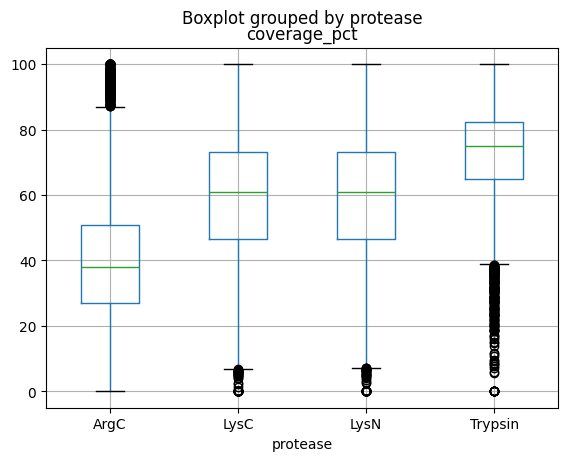

In [7]:
coverages_df = ps.compare_sequence_coverages(proteins, ps.enzyme_cleavage_patterns)

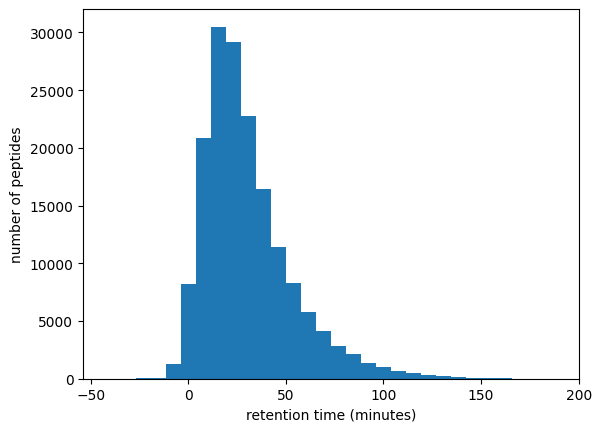

{'VTQMTPAPK': 18.7,
 'GAASNR': 3.8,
 'LGSFTR': 18.5,
 'KPQAR': 5.1,
 'GSMADVPK': 12.6,
 'LSGNHTFDTTQSK': 16.3,
 'LPHDMR': 17.7,
 'DQDLSK': 3.1,
 'DFGVK': 11.7,
 'TTLPER': 11.4,
 'YPGFK': 15.4,
 'EAAAK': 5.1,
 'DIYGWTGDASK': 18.6,
 'IAEGK': 8.8,
 'MAGGK': 7.6,
 'LPSEMK': 15.2,
 'QVTSLTK': 14.6,
 'DDFVHDK': 8.9,
 'EHLER': 9.5,
 'INPLDK': 15.9,
 'VELPETDCDQR': 12.9,
 'YSLEEK': 10.3,
 'EISIR': 15.7,
 'TPPSK': 4.0,
 'GNFGDVYK': 15.3,
 'SYVNGLPEEK': 17.2,
 'YLHEQR': 15.4,
 'YDPMK': 10.0,
 'SDVDLIK': 17.1,
 'YPLQNR': 15.9,
 'NSNTVR': 4.8,
 'LSTTQISK': 16.7,
 'NDIQALK': 15.9,
 'FDYLK': 19.8,
 'IEAIK': 17.3,
 'NVASYLQSNSSQEK': 16.4,
 'TIADIQK': 16.3,
 'AYAQGISK': 16.4,
 'MGEVDPNADYAK': 15.2,
 'EEVNDDYSK': 1.0,
 'DTIEK': 4.5,
 'YMAQR': 13.7,
 'SYSTEK': 2.4,
 'NIESK': 5.5,
 'TDLVK': 12.2,
 'MSSNAQVK': 11.9,
 'TAASPIER': 14.3,
 'QGTLDR': 7.4,
 'GNTANVIR': 15.6,
 'EEGYAK': 3.8,
 'LAADSK': 10.1,
 'SDGVAGLYR': 18.9,
 'FDSSVDR': 9.4,
 'LSVGEK': 12.5,
 'VAELER': 15.2,
 'HAEILSEK': 18.4,
 'SQQQTNSSNSISQ

In [8]:
pooled_peptides = sum(peptides.values(), [])
retention_times = ps.predict_lc_retention_times(pooled_peptides)

ps.plot_retention_time(retention_times)

selected_peptides = ps.select_retention_time_window(retention_times, lower_ret_time=0, upper_ret_time=20)
selected_peptides

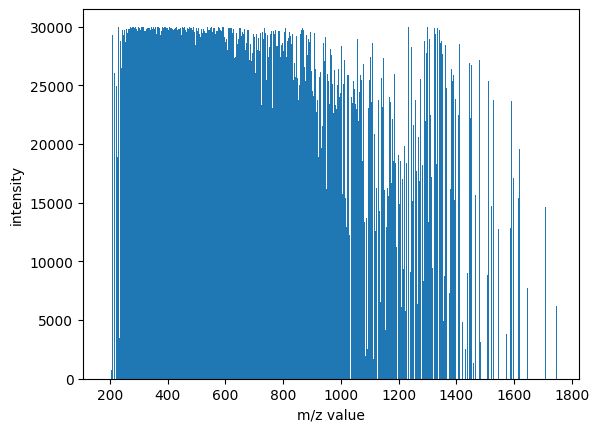

['D',
 'DI',
 'DIY',
 'DIYG',
 'DIYGW',
 'DIYGWT',
 'DIYGWTG',
 'DIYGWTGD',
 'DIYGWTGDA',
 'DIYGWTGDAS',
 'K',
 'SK',
 'ASK',
 'DASK',
 'GDASK',
 'TGDASK',
 'WTGDASK',
 'GWTGDASK',
 'YGWTGDASK',
 'IYGWTGDASK']

In [10]:
mol_mass_collection = ps.calculate_mol_mass_collection(selected_peptides, ps.amino_acid_mass_dalton)
mz_collection = ps.calculate_mz_collection(mol_mass_collection, charge=2)

ps.plot_spectrum(mz_collection.values())

sample_peptide = "DIYGWTGDASK"
fragments = ps.fragment_peptide(sample_peptide)
fragments

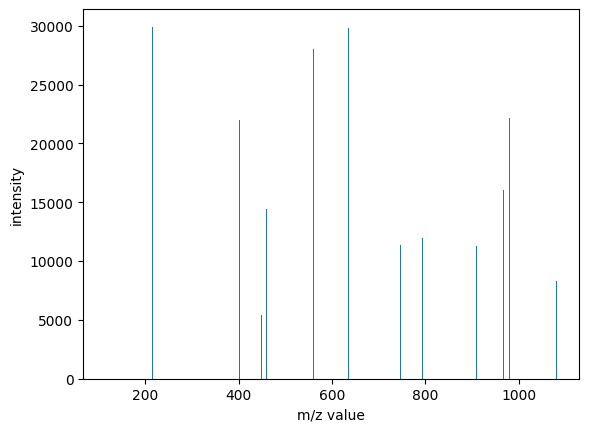

In [11]:
fragment_masses_ms2 = ps.calculate_mol_mass_collection(fragments, ps.amino_acid_mass_dalton)
fragment_mz2_collection = ps.calculate_mz_collection(fragment_masses_ms2, 1)

ps.plot_spectrum(fragment_mz2_collection.values())